# 随机森林算法

***

## 1.前置概念

**集成学习**
* 集成学习就是通过训练学习出多个估计器，当需要预测时通过结合器将多个估计器的结果整合起来当作最后的输出结果
<div align="center">
  <img src="./images/集成学习流程.png" width="500"/>
</div>

* 集成学习的优势是提升了单个估计器的通用性与鲁棒性，比单个估计器拥有更好的预测性能。
* 集成学习的另一个特点是能方便的进行并行化操作。

**Bagging算法**
* 定义：Bagging算法是一种集成学习算法，其全称为自助聚集算法（Bootstrap aggregating），由Bootstrap与Aggregating两部分组成。简单来说就是从训练集中进行子抽样（有放回的随机抽样）组成每个基模型所需要的子训练集，对所有基模型预测的结果进行综合，产生最终的预测结果：
<div align="center">
  <img src="./images/bagging算法.png" width="500"/>
</div>

* 示例：下图展示了Bagging 算法使用自助取样（Bootstrapping）生成多个子数据的示例
<div align="center">
  <img src="./images/bagging算法案例.png" width="500"/>
</div>
 
* 进行随机抽样的原因
    * 如果不进行随机抽样，每棵树的训练集都一样，那么最终训练出的树分类结果也是完全一样的
* 有放回地抽样的原因
    * 如果不是有放回的抽样，那么每棵树的训练样本都是不同的，都是没有交集的，这样每棵树都是“有偏的”，都是绝对“片面的”（当然这样说可能不对），也就是说每棵树训练出来都是有很大的差异的；而随机森林最后分类取决于多棵树（弱分类器）的投票表决。


## 2. 随机森林算法

**基础内容**
* 定义：随机森林是一种监督式算法，使用由众多决策树组成的一种集成学习方法，输出是对问题最佳答案的共识。随机森林可用于分类或回归。
    * 每次所使用的数据集都是是随机有放回选出的，同时随机选出部分特征作为输入
    * 可以看到随机森林算法是以决策树为估计器的Bagging算法。
* 随机森林算法流程：下面是随机森林算法的具体流程。
    * 在分类问题中，结合器选择多数分类结果作为最后的结果；
    * 在回归问题中，对结合器将多个回归结果取平均值作为最后的结果。
<div align="center">
  <img src="./images/随机森林算法流程.png" width="800"/>
</div>

* 总结：使用Bagging算法能降低过拟合的情况，从而带来了更好的性能。单个决策树对训练集的噪声非常敏感，但通过Bagging算法降低了训练出的多颗决策树之间关联性，有效缓解了上述问题。

**算法步骤**

假设训练集 T 的大小为 N ，特征数目为 M ，随机森林的大小为 K ，随机森林算法的具体步骤如下：

* 遍历随机森林的大小 K 次：
    * 从训练集 T 中有放回抽样的方式，取样N 次形成一个新子训练集 D
    * 随机选择 m 个特征，其中 m < M
    * 使用新的训练集 D 和 m 个特征，学习出一个完整的决策树
* 得到随机森林

上面算法中 m 的选择：对于分类问题，可以在每次划分时使用$\sqrt{M} $个特征，对于回归问题， 选择$
\frac{M}{3}$ 但不少于 5 个特征。

**优缺点**

* 随机森林算法的优点：

    1. 对于很多种资料，可以产生高准确度的分类器
    2. 可以处理大量的输入变量
    3. 可以在决定类别时，评估变量的重要性
    4. 在建造森林时，可以在内部对于一般化后的误差产生不偏差的估计
    5. 包含一个好方法可以估计丢失的资料，并且如果有很大一部分的资料丢失，仍可以维持准确度
    6. 对于不平衡的分类资料集来说，可以平衡误差
    7. 可被延伸应用在未标记的资料上，这类资料通常是使用非监督式聚类，也可侦测偏离者和观看资料
    8. 学习过程很快速

* 随机森林算法的缺点：

    1. 牺牲了决策树的可解释性
    2. 在某些噪音较大的分类或回归问题上会过拟合
    3. 在多个分类变量的问题中，随机森林可能无法提高基学习器的准确性

## 3.随机森林的鸢尾花分类预测

**随机森林API**

* class sklearn.ensemble.RandomForestClassifier(n_estimators=10, criterion=’gini’, max_depth=None, bootstrap=True, random_state=None, min_samples_split=2)

    * 随机森林分类器
    * **n_estimators：** integer，optional（default = 10）   森林里的树木数量120,200,300,500,800,1200
    * criteria：string，可选（default =“gini”）   分割特征的测量方法
    * **max_depth：** integer或None，可选（默认=无）树的最大深度 5, 8, 15, 25, 30
    * max_features="auto”, 每个决策树的最大特征数量
        * If "auto", then max_features=sqrt(n_features).   最大特征数量是总特征数量的平方根
        * If "sqrt", then max_features=sqrt(n_features) (same as "auto").   最大特征数量是总特征数量的平方根
        * If "log2", then max_features=log2(n_features).  最大特征数量是总特征数量的对数
        * If None, then max_features=n_features.  会用到所有的特征
    * bootstrap：boolean，optional（default = True）是否在构建树时使用放回抽样
    * min_samples_split: 节点划分最少样本数
    * min_samples_leaf: 叶子节点的最小样本数
* 超参数：n_estimator, max_depth, min_samples_split, min_samples_leaf

**实战项目：鸢尾花分类**

* 目标：用随机森林判断鸢尾花的品种（山鸢尾、变色鸢尾、维吉尼亚鸢尾）
* 工具：Python的sklearn库（代码仅需10行）
* 图像：
  <div align="center">
  <img src="./images/鸢尾花.png" width="600"/>
</div>
* 数据集：鸢尾花（iris）数据集，它共有4个属性列和一个品种类别列：
    * 属性：sepal length（萼片长度）、sepal width（萼片宽度）、petal length（花瓣长度）、petal width （花瓣宽度），单位都是厘米。
    * 品种：3个品种类别是Setosa、Versicolour、Virginica，样本数量150个，每类50个。

**第一步：导入包**

In [2]:
from sklearn.datasets import load_iris  # 加载数据
from sklearn.ensemble import RandomForestClassifier    # 随机森林的分类算法
from sklearn.model_selection import train_test_split   # 数据集的划分（训练和测试）

**第二步：加载数据与划分数据**

In [8]:
iris = load_iris()
print(iris)
X = iris.data     # 特征
y = iris.target   # 标签

# 数据集的划分
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

{'data': array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2],
       [4.6, 3.1, 1.5, 0.2],
       [5. , 3.6, 1.4, 0.2],
       [5.4, 3.9, 1.7, 0.4],
       [4.6, 3.4, 1.4, 0.3],
       [5. , 3.4, 1.5, 0.2],
       [4.4, 2.9, 1.4, 0.2],
       [4.9, 3.1, 1.5, 0.1],
       [5.4, 3.7, 1.5, 0.2],
       [4.8, 3.4, 1.6, 0.2],
       [4.8, 3. , 1.4, 0.1],
       [4.3, 3. , 1.1, 0.1],
       [5.8, 4. , 1.2, 0.2],
       [5.7, 4.4, 1.5, 0.4],
       [5.4, 3.9, 1.3, 0.4],
       [5.1, 3.5, 1.4, 0.3],
       [5.7, 3.8, 1.7, 0.3],
       [5.1, 3.8, 1.5, 0.3],
       [5.4, 3.4, 1.7, 0.2],
       [5.1, 3.7, 1.5, 0.4],
       [4.6, 3.6, 1. , 0.2],
       [5.1, 3.3, 1.7, 0.5],
       [4.8, 3.4, 1.9, 0.2],
       [5. , 3. , 1.6, 0.2],
       [5. , 3.4, 1.6, 0.4],
       [5.2, 3.5, 1.5, 0.2],
       [5.2, 3.4, 1.4, 0.2],
       [4.7, 3.2, 1.6, 0.2],
       [4.8, 3.1, 1.6, 0.2],
       [5.4, 3.4, 1.5, 0.4],
       [5.2, 4.1, 1.5, 0.1],
       [5.5, 4.2, 1.4, 0.2],
     

**第三步：训练模型**

In [9]:
model = RandomForestClassifier(n_estimators=200, max_depth=4)  #创建随机森林算法
model.fit(X_train, y_train)  # 学习训练集

RandomForestClassifier(max_depth=4, n_estimators=200)

**第四步：预测结果**

In [12]:
pradictions = model.predict(X_test)
pradictions # 预测结果

array([1, 0, 2, 1, 1, 0, 1, 2, 1, 1, 2, 0, 0, 0, 0, 1, 2, 1, 1, 2, 0, 2,
       0, 2, 2, 2, 2, 2, 0, 0, 0, 0, 1, 0, 0, 2, 1, 0, 0, 0, 2, 1, 1, 0,
       0])

In [11]:
y_test

array([1, 0, 2, 1, 1, 0, 1, 2, 1, 1, 2, 0, 0, 0, 0, 1, 2, 1, 1, 2, 0, 2,
       0, 2, 2, 2, 2, 2, 0, 0, 0, 0, 1, 0, 0, 2, 1, 0, 0, 0, 2, 1, 1, 0,
       0])

**第五步：计算分数**

In [15]:
acc = model.score(X_test, y_test)
acc

1.0

**第六步：特征重要性分析**

[0.09175111 0.02594799 0.4706134  0.4116875 ]


<BarContainer object of 4 artists>

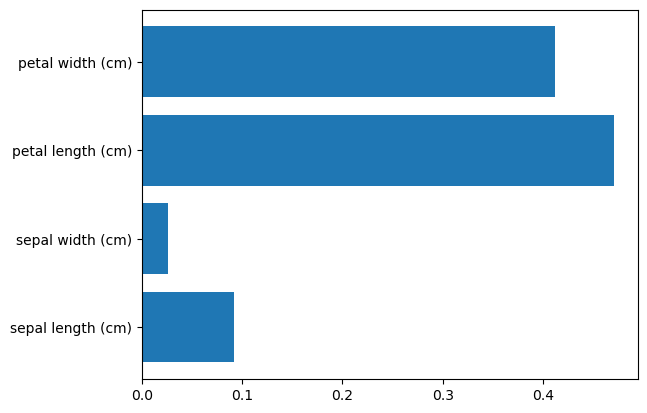

In [19]:
import matplotlib.pyplot as plt
print(model.feature_importances_)
plt.barh(iris.feature_names, model.feature_importances_)